<a href="https://colab.research.google.com/github/asegura4488/MetodosComputacionales2026/blob/main/Semana13/Optimize.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
from scipy.optimize import minimize

In [4]:
def f(v):
  x, y = v
  return x**2 + y**2

In [5]:
def restriccion(v):
  x, y = v
  return x + y - 4

In [10]:
constraints = [
    {'type': 'ineq', 'fun': restriccion}
]

In [12]:
bounds = [(0,None),(0,None)]

In [13]:
# semilla
x0 = [1,1]

In [14]:
# Optimizacion
result = minimize(f, x0, method='SLSQP', bounds=bounds, constraints=constraints)
print(result)

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 8.000000000000092
           x: [ 2.000e+00  2.000e+00]
         nit: 3
         jac: [ 4.000e+00  4.000e+00]
        nfev: 10
        njev: 3
 multipliers: [ 4.000e+00]


In [15]:
result.x

array([2., 2.])

In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [18]:
import os
os.chdir('/content/drive/MyDrive/ColabNotebooks/Cursos/MetodosComputacionales2026')

In [19]:
import pandas as pd

In [20]:
df = pd.read_csv('Semana13/Data/cuotas.csv')

In [21]:
df

,Partido,Local,Empate,Visitante
0,Santa,2.17,3.1,3.75
1,Millo,1.71,3.7,5.10


In [22]:
from typing import no_type_check_decorator
opciones = ['Local','Empate','Visitante']
n_partidos = len(df)

In [23]:
import itertools
combinaciones = list(itertools.product(opciones, repeat=n_partidos))

In [24]:
combinaciones

[('Local', 'Local'),
 ('Local', 'Empate'),
 ('Local', 'Visitante'),
 ('Empate', 'Local'),
 ('Empate', 'Empate'),
 ('Empate', 'Visitante'),
 ('Visitante', 'Local'),
 ('Visitante', 'Empate'),
 ('Visitante', 'Visitante')]

In [29]:
registros = []

for combo in combinaciones:
  cuota_total = 1.0
  etiqueta_partes = []

  for i, eleccion in enumerate(combo):
    partido = df.loc[i,"Partido"]
    cuota_total *= df.loc[i,eleccion]

    etiqueta_partes.append(f"{partido}:{eleccion}")

  etiqueta = "_".join(etiqueta_partes)
  registros.append({"Etiqueta":etiqueta, "Cuota":cuota_total})
  #print(cuota_total)

df_comb = pd.DataFrame(registros)

In [30]:
df_comb

,Etiqueta,Cuota
0,Santa:Local_Millo:Local,3.7107
1,Santa:Local_Millo:Empate,8.0290
2,Santa:Local_Millo:Visitante,11.0670
3,Santa:Empate_Millo:Local,5.3010
4,Santa:Empate_Millo:Empate,11.4700
5,Santa:Empate_Millo:Visitante,15.8100
6,Santa:Visitante_Millo:Local,6.4125
7,Santa:Visitante_Millo:Empate,13.8750
8,Santa:Visitante_Millo:Visitante,19.1250


In [34]:
n = df_comb.shape[0]
n

9

In [44]:
ganancias = df_comb['Cuota'].to_numpy()
ganancias

array([ 3.7107,  8.029 , 11.067 ,  5.301 , 11.47  , 15.81  ,  6.4125,
       13.875 , 19.125 ])

In [45]:
def retorno(w,ganancia,Capital):
  retorno = w*ganancia*Capital - Capital
  return retorno

In [46]:
w = np.ones(n)/n
w

array([0.11111111, 0.11111111, 0.11111111, 0.11111111, 0.11111111,
       0.11111111, 0.11111111, 0.11111111, 0.11111111])

In [47]:
retorno(w,ganancias,100000)

array([-58770.        , -10788.88888889,  22966.66666667, -41100.        ,
        27444.44444444,  75666.66666667, -28750.        ,  54166.66666667,
       112500.        ])

In [75]:
def fun_objetivo(w,ganancia,Capital):
  retorno = w*ganancia*Capital - Capital
  return np.std(retorno)

In [83]:
fun_objetivo(w,ganancias,1000)

np.float64(538.2074326935804)

In [84]:
def restriccion(w):
  return np.sum(w) - 1

In [85]:
constrainst = {
    "type": "eq",
    "fun": restriccion
}

In [86]:
bounds = [(0,1) for _ in range(n)]

In [87]:
w0 = np.ones(n)/n

In [93]:
result = minimize(fun_objetivo,
                  w0,
                  args=(ganancias,1000),
                  bounds=bounds,
                  constraints=constrainst)

In [94]:
result

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.0034501122655006466
           x: [ 2.442e-01  1.128e-01  8.186e-02  1.709e-01  7.899e-02
                5.730e-02  1.413e-01  6.530e-02  4.737e-02]
         nit: 52
         jac: [ 3.095e+02  2.172e+01  7.723e+02  1.049e+03 -1.160e+03
               -2.886e+03  5.016e+02 -7.123e+02 -1.573e+03]
        nfev: 604
        njev: 52
 multipliers: [ 9.624e+00]

In [95]:
pesos = result.x

<StemContainer object of 3 artists>

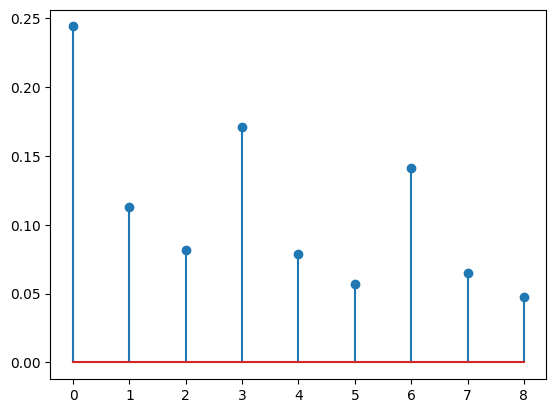

In [96]:
plt.stem(pesos)

In [98]:
retorn2 = retorno(pesos,ganancias,1000)

<StemContainer object of 3 artists>

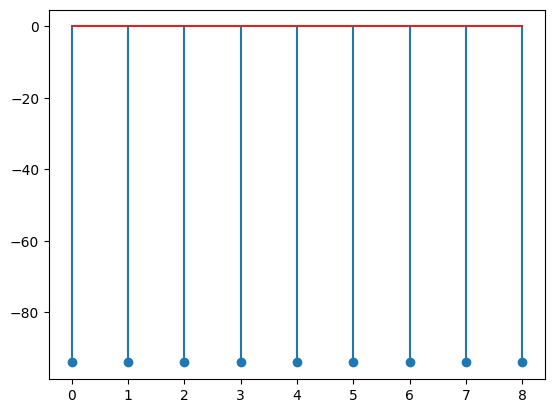

In [99]:
plt.stem(retorn2)